In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import imblearn
import sklearn
import pickle

import sklearn.decomposition as skdecomp
import sklearn.ensemble as skens
import sklearn.svm as sksvm
import sklearn.linear_model as sklin

from sklearn.model_selection import GridSearchCV,StratifiedGroupKFold,StratifiedKFold,KFold
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

from pychemauth.classifier.simca import SIMCA_Authenticator
from pychemauth.manifold.elliptic import EllipticManifold_Authenticator
from pychemauth.classifier.plsda import PLSDA
#from pychemauth.analysis.compare import Compare
from pychemauth.preprocessing.scaling import CorrectedScaler

from pychemauth.classifier.osr import OpenSetClassifier

from pychemauth_compare_ext import Compare_reg,make_boxplot,order_results,results_perform

2026-08-17 17:09:41.948800: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import multiphase_flow_utils
from multiphase_flow_utils import generate_models,extract_best_estimator
from multiphase_flow_utils import read_and_split_file,strip_constant,prune_threshold
from multiphase_flow_utils import fit_models,generate_kfolds,cross_validate
from multiphase_flow_utils import generate_kfolds,cross_validate,compute_scores
from multiphase_flow_utils import compute_fit,compute_vals,plot_fit,plot_vals

In [3]:
paper_models = [
    'PLS',
    'LASSO',
    'Ridge',
    'OLS',
    'ElasticNet',
    'Scaled RBF SVR',
    'Random Forest',
    'XGBoost'
]

In [4]:
file = 'combined_process.xlsx'
dataset_num = 'process' #'1+3'

study_pickle_file = file.split('.')[0] + '_triples_study.pkl'
ydata_col = 'Erro ([%])'

with open(study_pickle_file,'rb') as f:
    print(study_pickle_file)
    this_study = pickle.load(f)

combined_process_triples_study.pkl


In [5]:
def calibration_plots(study_data,study_predict):
    x,y = study_data
    predicted = study_predict(x)
    
    nplots = len(predicted)
    fig,axs = plt.subplots(nplots,2,figsize=(8,2*(nplots+1)),squeeze=False)
    
    for (name,pred),ax_cal,ax_res in zip(predicted.items(),axs[:,0],axs[:,1], ):
        ax_cal.plot(
            y,pred,
            ls='none',marker='o',markersize=1,color='r'
        )

        cal_line_limits = ax_cal.get_xticks()[[0,-1]]
        ax_cal.plot(cal_line_limits,cal_line_limits,color='k',lw=2)
        ax_cal.set_xlim(cal_line_limits)
        ax_res.plot(
            y,pred[:,None]-y.values,
            ls='none',marker='o',markersize=1,color='r'
        )
        ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)
        
def cvs_plots(study_data,cvs_dict,kfold_repeats):
    x,y = study_data
    
    yt = np.squeeze(y.values)
    #cvs_dict = this_study.cvs_dict
    #n_repeats = this_study.kfold_repeats

    nplots = len(cvs_dict)
    fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots+0.5),squeeze=False)

    for (name,cvs),ax_cal,ax_res in zip(cvs_dict.items(),axs[:,0],axs[:,1], ):

        coefs,covar,fit_err = compute_fit(yt,cvs,kfold_repeats)

        plot_vals(ax_cal,yt,cvs)
        plot_vals(ax_res,yt,cvs,resid=True)

        plot_fit(ax_cal,coefs,covar,fit_err)
        ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)
    return fig,axs
        

In [6]:
def calibration_plots(y,predicted,axs,size=1,color='r'):
    #x,y = study_data
    #predicted = study_predict(x)
    
    #nplots = len(predicted)
    #fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))
    
    for (name,pred),ax_cal,ax_res in zip(predicted.items(),axs[:,0],axs[:,1], ):
        ax_cal.plot(
            y,pred,
            ls='none',marker='o',markersize=size,color=color
        )

        cal_line_limits = ax_cal.get_xticks()[[0,-1]]
        ax_cal.plot(cal_line_limits,cal_line_limits,color='k',lw=2,zorder=-1)
        ax_cal.set_xlim(cal_line_limits)
        ax_res.plot(
            y,pred[:,None]-y.values,
            ls='none',marker='o',markersize=size,color=color
        )
        ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)

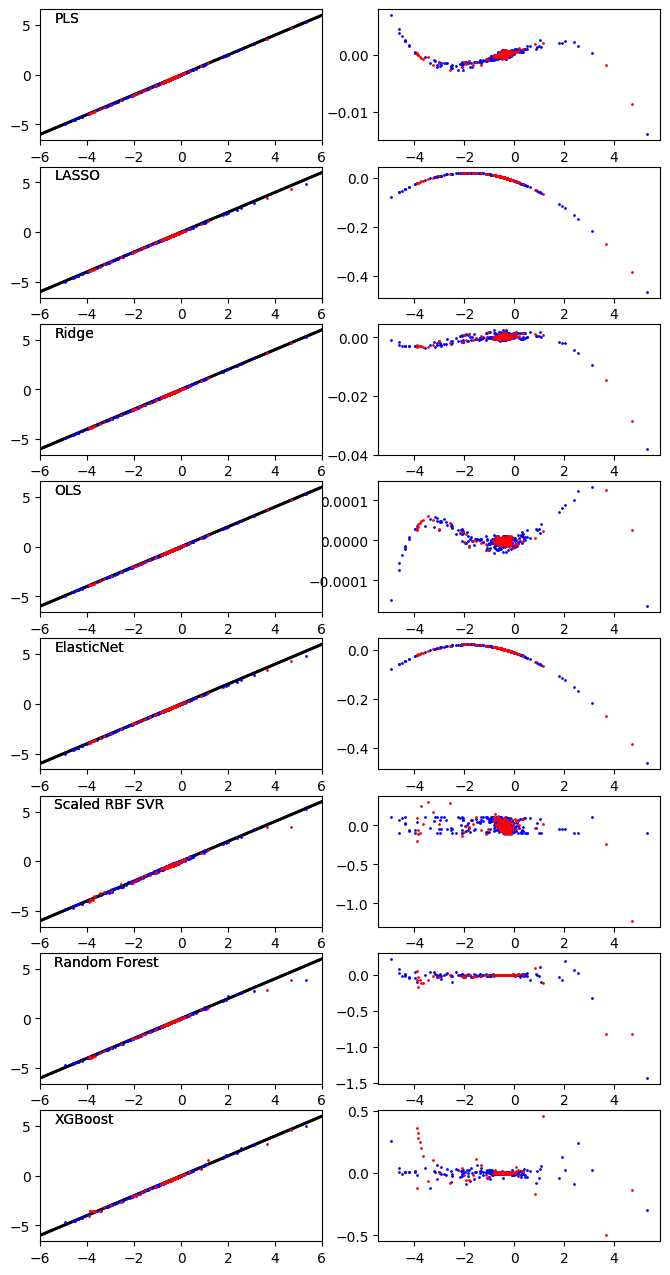

In [7]:
xtr,ytr = this_study.train
xte,yte = this_study.test

pred_tr = this_study.all_predict(xtr)
pred_te = this_study.all_predict(xte)

pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in paper_models}
pred_te = {mdl:this_study.all_predict(xte)[mdl] for mdl in paper_models}

nplots = len(pred_tr)
fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))

calibration_plots(ytr,pred_tr,axs,color='b')
calibration_plots(yte,pred_te,axs,color='r')

In [8]:
pred_tr

{'PLS': array([-2.08927491e-01, -1.95197041e-01, -2.29818114e-01, -3.10982266e+00,
        -2.58272836e-01, -2.15133950e-01, -4.09787659e-01, -1.86001866e-01,
        -2.91488380e-01,  4.50783062e-03, -5.74713188e-01, -7.43469933e-01,
        -1.44496717e-01, -3.76704316e-01, -3.59551410e-01, -5.96484370e-01,
        -4.59963702e+00, -1.40499633e-01, -3.51785985e-01, -5.40516130e-01,
        -1.71306488e-01, -2.35666743e-01, -6.46213316e-01, -2.44685922e-01,
        -4.37093249e+00, -2.24500781e+00, -1.72437319e-01, -2.01545692e-01,
        -1.91458498e-01, -7.14426589e-01, -5.88487654e-01, -4.19965801e-01,
        -1.13854032e+00, -6.54903527e-01, -7.10104497e-01, -3.83763548e-01,
        -2.40377324e-01, -3.21623289e-01, -5.75121076e-01, -1.11792212e-01,
        -1.15083462e+00, -4.63406857e-01, -7.81276228e-01, -2.62825141e-01,
        -2.41285463e-01, -3.65861391e-01, -2.75237104e-01, -1.20482110e-01,
         3.48591565e-01, -3.37862862e-01, -4.86085994e-01, -3.53100044e-01,
     

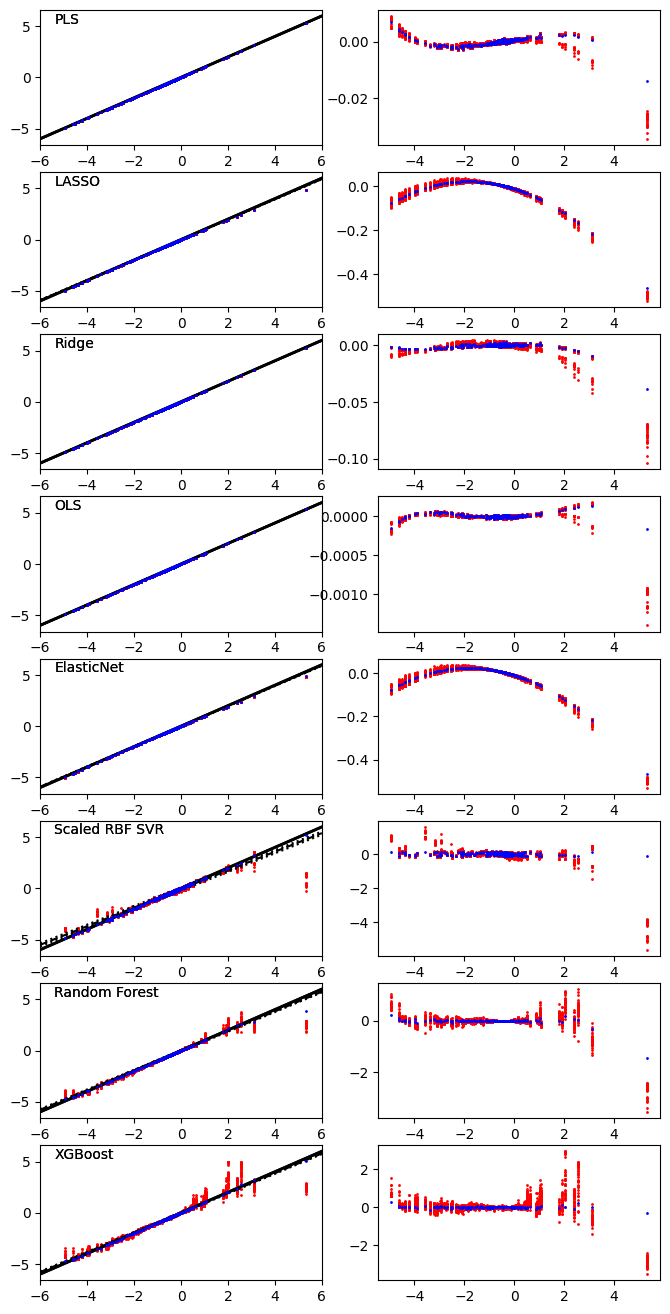

In [9]:
xtr,ytr = this_study.train
xte,yte = this_study.test

cvs_dict = this_study.cvs_dict

cvs_detailed = {
    key:cvs_dict[key] for key in paper_models
}
fig,axs = cvs_plots(this_study.train,cvs_detailed,this_study.kfold_repeats)
pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in paper_models}

#fig,axs = cvs_plots(this_study.train,cvs_dict,this_study.kfold_repeats)
calibration_plots(ytr,pred_tr,axs,color='b')

In [10]:
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_study.cv_score(score_name=name,score_fun=metric)

mae
rmse
r2
mape
medae
maxe


In [11]:
paper_models = [
    'PLS',
    'LASSO',
    'Ridge',
    'OLS',
    'ElasticNet',
    'Scaled RBF SVR',
    'Random Forest',
    'XGBoost'
]

In [12]:
scores_train = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.train,score_name=name,score_fun=metric)
    scores_train = dict(**scores_train,**this_score)
scores_train = {
    metric:{mdl:this_scores[mdl] for mdl in paper_models}
    for metric,this_scores in scores_train.items()
}
pd.DataFrame.from_dict(scores_train)

,mae,rmse,r2,mape,medae,maxe
PLS,0.000436,0.000911,0.999999,0.001354,0.000199,0.013951
LASSO,0.009616,0.025931,0.999054,0.025086,0.004971,0.464907
Ridge,0.000617,0.001748,0.999996,0.001750,0.000315,0.038096
OLS,0.000008,0.000017,1.000000,0.000023,0.000004,0.000165
ElasticNet,0.009609,0.025919,0.999054,0.025047,0.004965,0.464711
Scaled RBF SVR,0.050700,0.058772,0.995138,0.183165,0.050627,0.100464
Random Forest,0.006715,0.059217,0.995064,0.007167,0.000400,1.429453
XGBoost,0.007077,0.022645,0.999278,0.020451,0.001920,0.295146


In [13]:
scores_test = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.test,score_name=name,score_fun=metric)
    scores_test = dict(**scores_test,**this_score)
scores_test = {
    metric:{mdl:this_scores[mdl] for mdl in paper_models}
    for metric,this_scores in scores_test.items()
}
pd.DataFrame.from_dict(scores_test)

,mae,rmse,r2,mape,medae,maxe
PLS,0.000428,0.000893,0.999999,0.001067,0.000202,0.008544
LASSO,0.010812,0.037876,0.998604,0.019005,0.004354,0.385276
Ridge,0.000861,0.002637,0.999993,0.001684,0.000376,0.028405
OLS,0.000009,0.000016,1.000000,0.000020,0.000005,0.000126
ElasticNet,0.010808,0.037858,0.998605,0.018979,0.004358,0.385101
Scaled RBF SVR,0.062860,0.120239,0.985930,0.156764,0.052048,1.223025
Random Forest,0.017057,0.093210,0.991545,0.011215,0.000947,0.824111
XGBoost,0.024814,0.077933,0.994089,0.025350,0.003128,0.499961


Text(0.5, 0, '$R^2$ score')

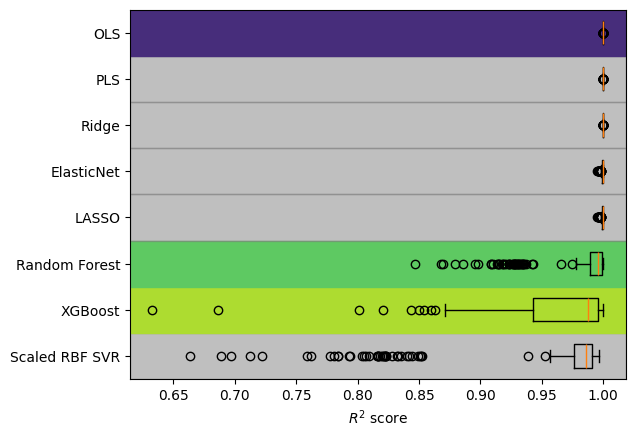

In [14]:
scores_dict = this_study.cv_scores['r2']
scores_dict = {mdl:scores_dict[mdl] for mdl in paper_models}
make_boxplot(scores_dict,this_study.kfold_repeats)
plt.gca().set_xlabel(r'$R^2$ score')

In [15]:
order = order_results(scores_dict)
order

['OLS',
 'PLS',
 'Ridge',
 'ElasticNet',
 'LASSO',
 'Random Forest',
 'XGBoost',
 'Scaled RBF SVR']

Text(0.5, 0, 'Median absolute error')

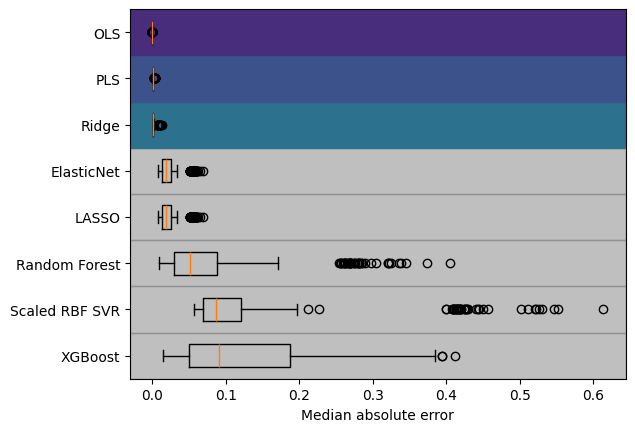

In [16]:
scores_dict = this_study.cv_scores['rmse']
scores_dict = {mdl:scores_dict[mdl] for mdl in paper_models}
make_boxplot(scores_dict,this_study.kfold_repeats,reverse=False)
plt.gca().set_xlabel('Median absolute error')

In [17]:
perfs = results_perform(scores_dict,this_study.kfold_repeats,alpha=0.05,reverse=False)
best_model = perfs[0][0]
good_models = []
for perf in perfs:
    if not perf[-1]: good_models += [perf[0]]

In [18]:
best_model,good_models

('OLS',
 ['OLS',
  'PLS',
  'Ridge',
  'ElasticNet',
  'LASSO',
  'Random Forest',
  'Scaled RBF SVR',
  'XGBoost'])

In [19]:
good_models[:1]

['OLS']

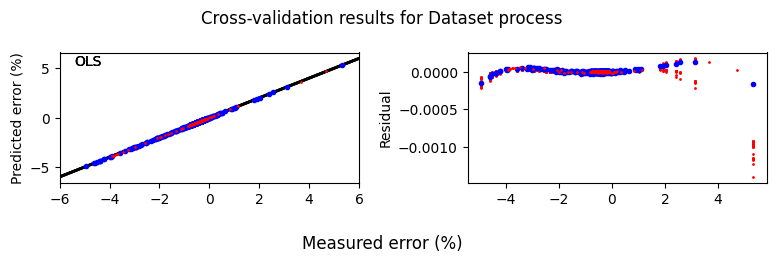

In [20]:
names_detailed = good_models[:1]
cvs_detailed = {
    key:cvs_dict[key] for key in names_detailed
}
fig,axs = cvs_plots(this_study.train,cvs_detailed,this_study.kfold_repeats)

xtr,ytr = this_study.train
xte,yte = this_study.test

pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in names_detailed}
pred_te = {mdl:this_study.all_predict(xte)[mdl] for mdl in names_detailed}

nplots = len(pred_tr)
#fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))

calibration_plots(ytr,pred_tr,axs,color='b',size=3)
calibration_plots(yte,pred_te,axs,color='r')

for ax_row in axs:
    ax_row[0].set_ylabel('Predicted error (%)')
    ax_row[1].set_ylabel('Residual')
    
fig.suptitle(
    'Cross-validation results for Dataset {}'.format(dataset_num), 
)
fig.supxlabel('Measured error (%)')
fig.tight_layout()

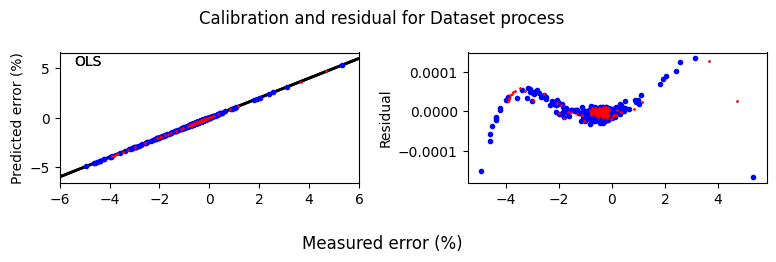

In [21]:
xtr,ytr = this_study.train
xte,yte = this_study.test

pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in names_detailed}
pred_te = {mdl:this_study.all_predict(xte)[mdl] for mdl in names_detailed}

nplots = len(pred_tr)
fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots+0.5),squeeze=False)

calibration_plots(ytr,pred_tr,axs,color='b',size=3)
calibration_plots(yte,pred_te,axs,color='r')

fig.suptitle(
    'Calibration and residual for Dataset {}'.format(dataset_num), 
)
fig.supxlabel('Measured error (%)')
for ax_row in axs:
    ax_row[0].set_ylabel('Predicted error (%)')
    ax_row[1].set_ylabel('Residual')
fig.tight_layout()

In [22]:
bad_models = [mdl for mdl,score in scores_test['r2'].items() if score < 0]
if len(bad_models)>0:
    xtr,ytr = this_study.train
    xte,yte = this_study.test

    pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in bad_models}
    pred_te = {mdl:this_study.all_predict(xte)[mdl] for mdl in bad_models}

    score_list = [scores_test['r2'][mdl] for mdl in bad_models]

    nplots = len(pred_tr)
    fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots+0.5),squeeze=False)

    calibration_plots(ytr,pred_tr,axs,color='b',size=3)
    calibration_plots(yte,pred_te,axs,color='r',size=3)

    fig.suptitle(
        'Calibration and residual for Dataset {}'.format(dataset_num), 
    )
    fig.supxlabel('Measured error (%)')
    for ax_row,score in zip(axs,score_list):
        ax_row[0].set_ylabel('Predicted error (%)')
        ax_row[1].set_ylabel('Residual')
        ax_row[0].text(
            0.95,0.05,'{:6.3f}'.format(score),
            ha='right',va='bottom',
            transform=ax_row[0].transAxes)
        print(score)
    fig.tight_layout()

In [23]:
import shap

In [24]:
med = np.median(this_study.train[0],axis=0)[None,:,]
print(med.shape)

def f(x):
    return this_study.best_models['Ridge'].predict(x)
    #return this_study.best_models[names_detailed[0]].predict(x)
    #return this_study.best_models[good_models[4]].predict(x)


ex1 = shap.Explainer(f,med)
shap_train = ex1(this_study.train[0],max_evals=1000)
shap_values = ex1(this_study.test[0],max_evals=1000)

(1, 24)


In [25]:
shap_train.feature_names

['Temp. (°C)',
 'Visc. (Pa.s)',
 'Reynolds x 10-3',
 'SOS (m/s)',
 'α·λ (#)',
 'N2 (%)',
 'Ar (%)',
 'Q Vol / Vel (m²)',
 '(Temp. (°C))²',
 '(Visc. (Pa.s))²',
 '(Reynolds x 10-3)²',
 '(SOS (m/s))²',
 '(α·λ (#))²',
 '(N2 (%))²',
 '(Ar (%))²',
 '(Q Vol / Vel (m²))²',
 '(Temp. (°C))³',
 '(Visc. (Pa.s))³',
 '(Reynolds x 10-3)³',
 '(SOS (m/s))³',
 '(α·λ (#))³',
 '(N2 (%))³',
 '(Ar (%))³',
 '(Q Vol / Vel (m²))³']

In [26]:
shap_train#[:,[0,1,3,5,6,7,8]]

.values =
array([[-3.83193581e-03, -6.19058612e-04, -1.51746663e-03, ...,
        -1.61612004e-03, -7.17286654e-04, -2.17467512e-01],
       [ 9.11543216e-03,  4.58309040e-03,  8.47526814e-05, ...,
        -3.27974183e-03,  0.00000000e+00, -2.32215387e-01],
       [ 8.24683774e-04, -2.51833133e-03,  1.67428761e-04, ...,
        -1.61612004e-03, -7.17327953e-04, -1.95058473e-01],
       ...,
       [ 1.56633879e-02,  9.21829672e-03, -2.72204065e-03, ...,
        -4.08005642e-03,  0.00000000e+00, -4.26927938e-01],
       [-2.40968250e-03,  2.24411981e-03,  1.33051161e-04, ...,
        -2.24105564e-03, -5.02318318e-04, -1.98159478e-01],
       [-2.74336996e-03, -1.10810243e-02,  9.58946319e-04, ...,
         0.00000000e+00, -1.02585809e-02,  3.47798258e-02]])

.base_values =
array([-0.40922198, -0.40922198, -0.40922198, -0.40922198, -0.40922198,
       -0.40922198, -0.40922198, -0.40922198, -0.40922198, -0.40922198,
       -0.40922198, -0.40922198, -0.40922198, -0.40922198, -0.40922198,
 

Text(0.5, 1.0, 'SHAP values for Dataset process: training set')

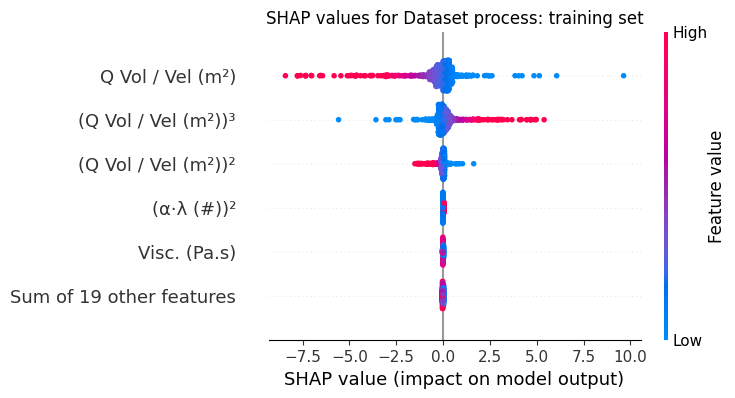

In [27]:
shaps = shap_train#[:,[0,1,3,5,6,7,8]]
segment = 'training'
title = "SHAP values for Dataset {num}: {segm} set".format(
    num = dataset_num,
    segm=segment,
)

shap.plots.beeswarm(
    shaps,
    max_display=6,
    plot_size=(6,4),
    order=shaps.abs.max(0),
    show=False
)
fig,ax = plt.gcf(),plt.gca()
ax.set_title(title)


Text(0.5, 1.0, 'SHAP values for Dataset process: test set')

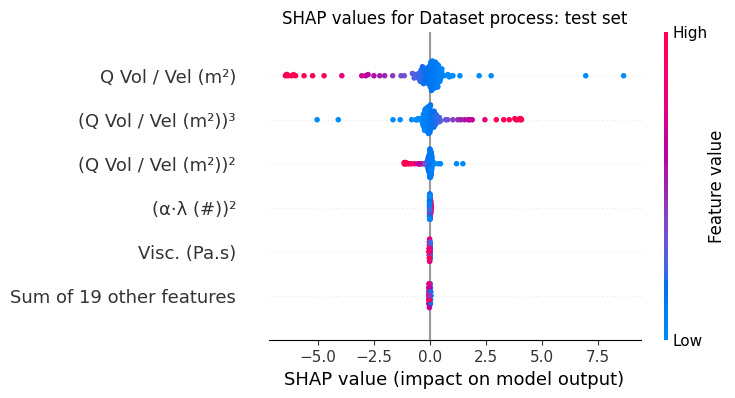

In [28]:
shaps = shap_values#[:,[0,1,3,5,6,7,8]]
segment = 'test'
title = "SHAP values for Dataset {num}: {segm} set".format(
    num = dataset_num,
    segm=segment,
)

shap.plots.beeswarm(
    shaps,
    max_display=6,
    plot_size=(6,4),
    order=shaps.abs.max(0),
    show=False
)
fig,ax = plt.gcf(),plt.gca()
ax.set_title(title)


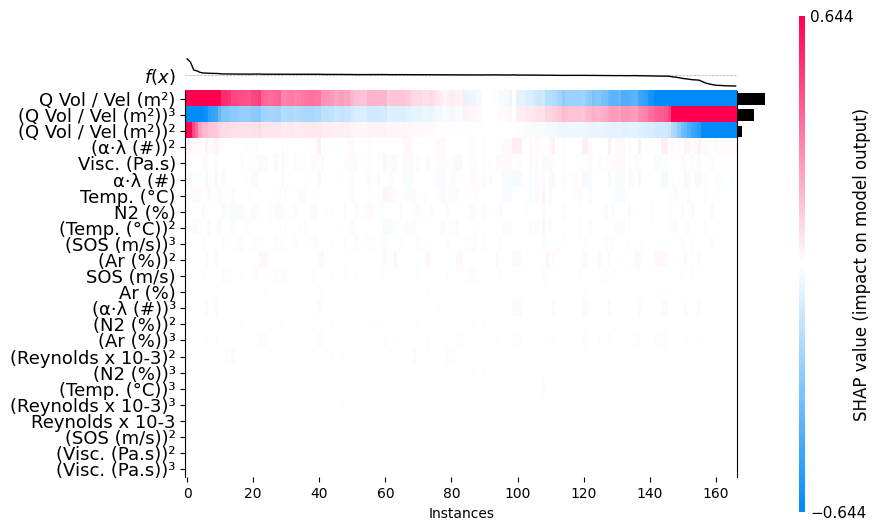

<Axes: xlabel='Instances'>

In [29]:
shap.plots.heatmap(shap_values,max_display=50)

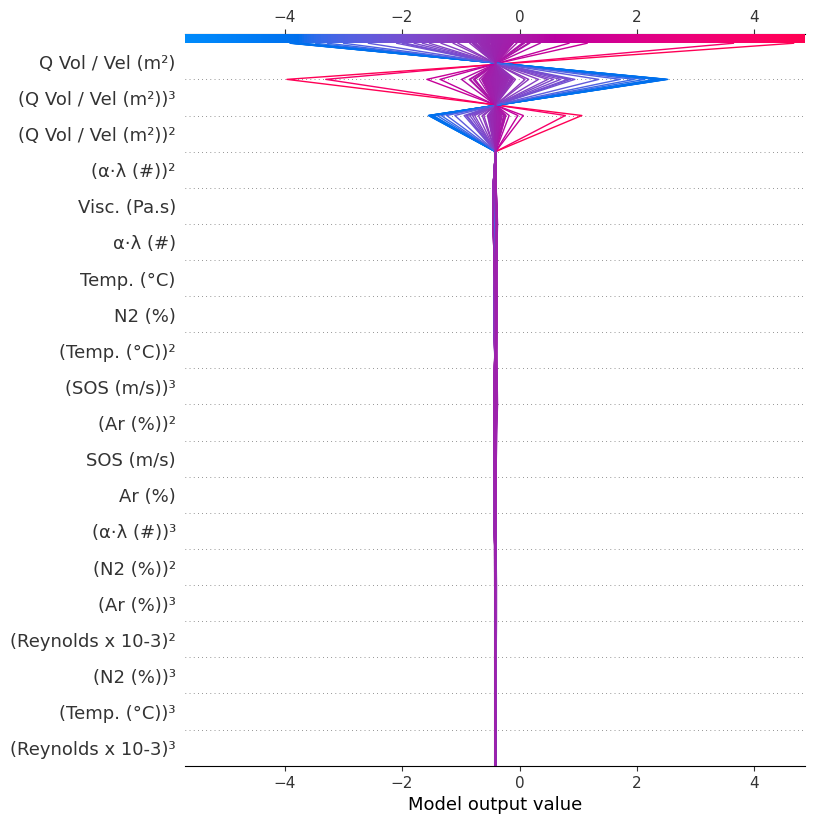

In [30]:
shap.decision_plot(
    shaps.base_values[0],
    shaps.values,
    feature_names=shaps.feature_names
)

In [31]:
this_study.cvs_dict

{'OLS': [array([-2.09120563e-01, -1.95436467e-01, -2.29905734e-01, -3.10775765e+00,
         -2.58511203e-01, -2.15137344e-01, -4.09986318e-01, -1.85849624e-01,
         -2.91487952e-01,  4.27755616e-03, -5.74592315e-01, -7.43410626e-01,
         -1.44514383e-01, -3.76864612e-01, -3.59496487e-01, -5.96447079e-01,
         -4.60437616e+00, -1.41196125e-01, -3.51949253e-01, -5.40661362e-01,
         -1.71279436e-01, -2.35905805e-01, -6.46209237e-01, -2.44893464e-01,
         -4.37349971e+00, -2.24239951e+00, -1.72360231e-01, -2.02085038e-01,
         -1.91648396e-01, -7.14308313e-01, -5.88187610e-01, -4.20027009e-01,
         -1.13765000e+00, -6.54723708e-01, -7.10044614e-01, -3.83665021e-01,
         -2.40455889e-01, -3.21561698e-01, -5.75099187e-01, -1.12509000e-01,
         -1.14987954e+00, -4.63704833e-01, -7.80874539e-01, -2.62744493e-01,
         -2.41608684e-01, -3.65770788e-01, -2.75128272e-01, -1.20381962e-01,
          3.47688461e-01, -3.37737680e-01, -4.86247016e-01, -3.534352

In [32]:
import matplotlib

In [33]:
scores = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.train,score_name=name,score_fun=metric)
    #print(this_score)
    scores = dict(**scores,**this_score)

pd.DataFrame.from_dict(scores)

,mae,rmse,r2,mape,medae,maxe
OLS,0.000008,0.000017,1.000000,0.000023,0.000004,0.000165
PLS,0.000436,0.000911,0.999999,0.001354,0.000199,0.013951
Linear SVR,0.046350,0.057355,0.995370,0.156795,0.046513,0.498340
Pareto Poly SVR,0.411542,0.853198,-0.024584,1.046543,0.173568,5.751794
Scaled Poly SVR,0.049039,0.058549,0.995175,0.186288,0.045848,0.100521
RBF SVR,0.396836,0.832146,0.025355,0.937362,0.161380,5.288373
Pareto RBF SVR,0.089517,0.092769,0.987887,0.346516,0.099817,0.100502
Scaled RBF SVR,0.050700,0.058772,0.995138,0.183165,0.050627,0.100464
LASSO,0.009616,0.025931,0.999054,0.025086,0.004971,0.464907
Ridge,0.000617,0.001748,0.999996,0.001750,0.000315,0.038096


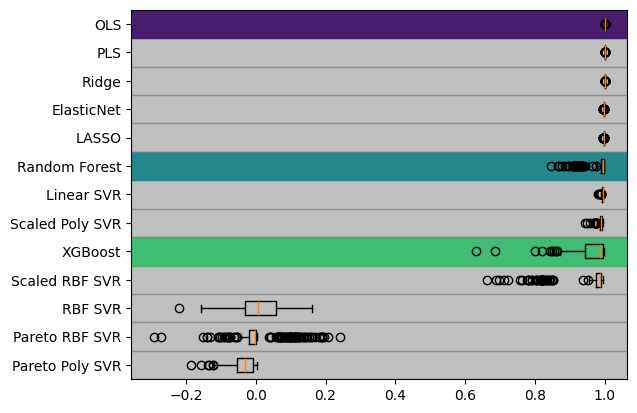

In [34]:
scores_dict = this_study.cv_scores['r2']
make_boxplot(scores_dict,this_study.kfold_repeats)

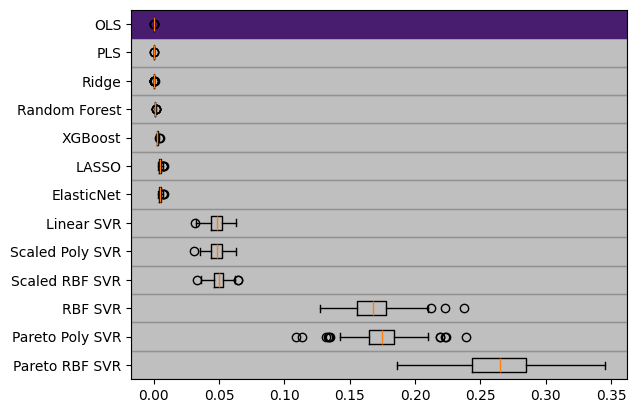

In [35]:
scores_dict = this_study.cv_scores['medae']
make_boxplot(scores_dict,this_study.kfold_repeats,reverse=False)

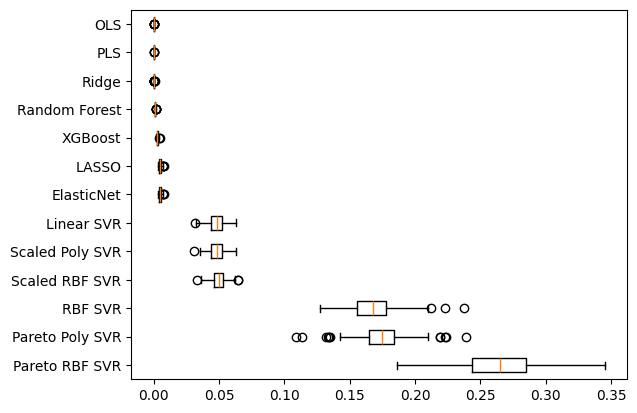

In [36]:
scores_dict = this_study.cv_scores['medae']

# ignore = np.nan
# if np.isnan(ignore):
#     key = lambda k: np.median(
#         np.asarray(scores_dict[k])[~np.isnan(scores_dict[k])]
#     )
# else:
#     key = lambda k: np.median(
#         np.asarray(scores_dict[k])[np.asarray(scores_dict[k]) != ignore]
#     )

# order = sorted(scores_dict, key=key, reverse=False)

order = order_results(scores_dict,reverse=False)

fig,ax = plt.subplots()

h = ax.boxplot(
    [scores_dict[name] for name in order][::-1],
    #[scr for name,scr in scores_dict.items()],
    tick_labels=order[::-1],
    vert=False
)
#ax.invert_xaxis()
#ax.set_ylim(-1,1)

#for name,scr in scores_dict.items():
#    ax.boxplot(scr)